# NEI explorer: build the data from the manuscript tables

Every index of the 165 networks (63 non-road + 102 road) is read from the **current manuscript PDF** (`Project_NEI.pdf`, 2026-11-09, text layer via `pdftotext -layout`), so the explorer shows exactly the printed numbers. The LaTeX source (`Project_NEI (typeA) 1102.tex`) supplies what the PDF text cannot: the row order, the category header and marker macro of each row, the colours, and the block-model null table (`tab:sbm-null`), which the PDF does not print. Every value is cross-checked between the two, and the differences are listed in Sec. 2b.

| table | rows | indices |
|---|---|---|
| Tables S2, S3, S4 (PDF) | 19 + 44 + 102 | $N$, $E$, $\ell_{uv}$, $\mathcal I_{\rm real}$ ($M=500$), $\langle\mathcal I\rangle_{\rm deg}$, $\langle\mathcal I\rangle_{\rm gnm}$, $\mathcal S_{\rm real}$, $\langle\mathcal S\rangle_{\rm deg}$, $\langle\mathcal S\rangle_{\rm gnm}$, $\mathcal C_{\rm deg}$, $\mathcal C_{\rm gnm}$ (+ BH flag $^*$, $^\dagger$) |
| Table S6 (PDF) | 165 | $\bar{\mathcal I}_{\rm real}$, $s_{\rm block}$, $\hat{\mathcal I}_{50}$, $\hat{\mathcal S}_{50}$, $\bar{\mathcal I}_{\rm real}/\mathcal I_{\rm real}$ |
| `tab:sbm-null` (tex 1102 only; rows whose $\bar{\mathcal I}_{\rm real}$, $\langle\mathcal I\rangle_{\rm gnm}$ or $\langle\mathcal I\rangle_{\rm deg}$ differ from the PDF are left empty) | 63 | $B$, $B_{\rm dc}$, $\langle\mathcal I\rangle_{\rm sbm}$, $\langle\mathcal I\rangle_{\rm dcsbm}$, $\mathcal C_{\rm sbm}$, $\mathcal C_{\rm dcsbm}$, $R$ |
| Table S8 (PDF) | 63 | $B$, $B_{\rm dc}$, $\mathcal I_{\rm inter}$, $\mathcal I_{\rm intra}$ of the $B$ partition (gnm, SBM, real) and of the $B_{\rm dc}$ partition (deg, DC-SBM, real) |

Derived: $\langle k\rangle=2E/N$, $\sqrt{\mathcal I_{\rm real}}$, $\sqrt{\mathcal S_{\rm real}}/\mathcal I_{\rm real}$, $\mathcal I_{\rm intra}/\mathcal I_{\rm inter}$ (real).

**Category, marker and colour** are those of SM Sec. I: the `\cat{name}{marker}{n}` list and the `\definecolor` lines of the same file; each table row takes the marker macro of its block header. The counts per category are checked against the $n$ of the SM text.

Outputs (`data/`): `nei_indices.csv` (one row per network), `nei_data.js` (the same + variable registry + category styles, loaded by `index.html`).

In [1]:
from pathlib import Path
import re, json
import numpy as np
import pandas as pd

HONE = Path.home() / "Library/CloudStorage/GoogleDrive-dotchgahyoun@gmail.com/내 드라이브/Project-HONE"
TEX = HONE / "NEI-typeA-review-2026-11-02" / "Project_NEI (typeA) 1102.tex"   # change here for a new revision
PDF = Path.home() / "Downloads" / "Project_NEI.pdf"                              # current manuscript (values)
REPO = Path.cwd()                                                              # run from the repository root
(REPO / "data").mkdir(exist_ok=True)
tex = TEX.read_text(encoding="utf-8")
print(TEX.name, len(tex))

Project_NEI (typeA) 1102.tex 149909


## 1. Categories, markers and colours (SM Sec. I)

In [2]:
COLORS = {k: "#" + v.upper() for k, v in re.findall(r"\\definecolor\{(c\w+)\}\{HTML\}\{([0-9A-Fa-f]{6})\}", tex)}

def parse_marker(s):
    """manuscript marker macro -> (shape id, colour key)"""
    m = re.search(r"\\mkpoly\{(c\w+)\}\{(\d+)\}\{(-?\d+)\}", s)
    if m:
        shape = {("3", "0"): "triangle-up", ("3", "180"): "triangle-down", ("3", "90"): "triangle-left",
                 ("3", "-90"): "triangle-right", ("5", "0"): "pentagon", ("6", "0"): "hexagon",
                 ("8", "0"): "octagon"}[(m.group(2), m.group(3))]
        return shape, m.group(1)
    m = re.search(r"\\mk(circle|square|diamond|thindiamond|plus|cross|star)\{(c\w+)\}", s)
    return m.group(1), m.group(2)

sm = tex[tex.index(r"\section{Category-specific markers and colors}"):]
sm = sm[: sm.index(r"\label{tab:") if r"\label{tab:" in sm[:4000] else 4000]
CATS = []
for name, mk, n in re.findall(r"\\cat\{([^}]*)\}\{(\\mk\w+\{c\w+\}(?:\{-?\d+\}\{-?\d+\})?)\}\{(\d+)\}", sm):
    shape, ckey = parse_marker(mk)
    CATS.append(dict(key=ckey, name=name, shape=shape, color=COLORS[ckey], n_sm=int(n),
                     group="road" if ckey in ("cAsia", "cAfrica", "cEurope", "cLatinAmerica", "cUS", "cRoadOther") else "non-road"))
cats = pd.DataFrame(CATS)
assert cats.key.is_unique and len(cats) == 20, cats
cats

,key,name,shape,color,n_sm,group
0,cSocial,social,diamond,#D45087,14,non-road
1,cBrain,brain,star,#1F4E79,6,non-road
2,cPower,power,plus,#6A5ACD,6,non-road
3,cRetweet,retweet,circle,#E76F51,6,non-road
4,cInteraction,interaction,cross,#B07AA1,5,non-road
5,cBiological,biological,pentagon,#4C9F70,4,non-road
6,cCollaboration,collaboration,square,#E9C46A,4,non-road
7,cWeb,web,hexagon,#8C6D31,4,non-road
8,cChemistry,chemistry,triangle-left,#C94F7C,3,non-road
9,cEcology,ecology,triangle-right,#3D9970,2,non-road


## 2. Parse the tables

In [3]:
def segment(label):
    """from \label{label} to the next table label: covers the continuation tabulars of long tables"""
    i = tex.index(r"\label{" + label + "}")
    nxt = [m.start() for m in re.finditer(r"\\label\{tab:", tex) if m.start() > i]
    return tex[i: nxt[0] if nxt else len(tex)]

def clean_name(c):
    return re.sub(r"~\\cite\{[^}]*\}|\$\^\{[^}]*\}\$", "", c).strip()

def val(c):
    """table cell -> float (nan for ---, \ph); handles a\!\times\!10^{b} and superscript flags"""
    s = re.sub(r"\$\^\{[^}]*\}\$", "", c).strip()
    m = re.fullmatch(r"\$?(-?\d+(?:\.\d+)?)\\!\\times\\!10\^\{(-?\d+)\}\$?", s)
    if m:
        return float(m.group(1)) * 10 ** int(m.group(2))
    return float(s) if re.fullmatch(r"-?\d+(\.\d+)?", s) else np.nan

def rows_of(label, ncol):
    out, header, marker = [], None, None
    for line in segment(label).splitlines():
        s = line.strip()
        if s.startswith(r"\multicolumn") and r"\mk" in s:
            header = re.search(r"\\textit\{([^~}]*)", s).group(1).strip()
            marker = parse_marker(s)
        elif s.startswith(r"\quad"):
            c = [x.strip() for x in s[len(r"\quad"):].rstrip("\\").rstrip().split("&")]
            assert len(c) == ncol, (label, s)
            out.append((header, marker, c))
    return out

ELL = {"1": "1", r"$\omega$": "ω", r"$1/\omega$": "1/ω", r"$d_{\rm gc}$": "d_gc", r"$d_{\rm line}$": "d_line"}
main = []
for label in ("tab:real-orig", "tab:real-added", "tab:road"):
    for header, (shape, ckey), c in rows_of(label, 12):
        main.append(dict(network=clean_name(c[0]), table=label, header=header, cat=ckey, shape_row=shape,
                         flags_input="".join(re.findall(r"\$\^\{([^}]*)\}\$", c[0]) + re.findall(r"\$\^\{([^}]*)\}\$", c[2])),
                         N=val(c[1]), E=val(c[2]), ell=ELL[c[3]],
                         I_real=val(c[4]), I_deg=val(c[5]), I_gnm=val(c[6]),
                         S_real=val(c[7]), S_deg=val(c[8]), S_gnm=val(c[9]),
                         C_deg=val(c[10]), C_gnm=val(c[11]),
                         BH_deg="^{*}" in c[10], BH_gnm="^{*}" in c[11],
                         floor_dagger=r"\dagger" in c[4] or r"\dagger" in c[0]))
df = pd.DataFrame(main)
assert df.network.is_unique, df.network[df.network.duplicated()]

blk = pd.DataFrame([dict(network=clean_name(c[0]), Ibar_real=val(c[1]), s_block=val(c[2]), I50=val(c[3]), S50=val(c[4]),
                         C_deg_blk=val(c[5]), C_gnm_blk=val(c[6]), Ibar_over_I=val(c[7]))
                    for _, _, c in rows_of("tab:block-audit", 8)])

def Rsplit(s, i):
    p = s.split("/")[i]
    return float(p) if p.isdigit() else np.nan
sbm = pd.DataFrame([dict(network=clean_name(c[0]), B=val(c[2]), B_dc=val(c[3]), Ibar_real_sbm=val(c[4]),
                         I_gnm_sbm=val(c[5]), I_sbm=val(c[6]), I_deg_sbm=val(c[7]), I_dcsbm=val(c[8]),
                         C_sbm=val(c[9]), C_dcsbm=val(c[10]), R_sbm=Rsplit(c[11], 0), R_dcsbm=Rsplit(c[11], 1))
                    for _, _, c in rows_of("tab:sbm-null", 12)])

II = ["Iinter_B_gnm", "Iinter_B_sbm", "Iinter_B_real", "Iintra_B_gnm", "Iintra_B_sbm", "Iintra_B_real",
      "Iinter_Bdc_deg", "Iinter_Bdc_dcsbm", "Iinter_Bdc_real", "Iintra_Bdc_deg", "Iintra_Bdc_dcsbm", "Iintra_Bdc_real"]
ii = pd.DataFrame([dict(network=clean_name(c[0]), **{k: val(v) for k, v in zip(II, c[4:])}) for _, _, c in rows_of("tab:intra-inter", 16)])

for name, t in (("block-audit", blk), ("sbm-null", sbm), ("intra-inter", ii)):
    miss = set(t.network) - set(df.network)
    assert not miss, (name, miss)
    print(f"{name}: {len(t)} rows, all names found in the main tables")
df = df.merge(blk, on="network", how="left").merge(sbm, on="network", how="left").merge(ii, on="network", how="left")
print(len(df), "networks")

block-audit: 165 rows, all names found in the main tables
sbm-null: 63 rows, all names found in the main tables
intra-inter: 63 rows, all names found in the main tables
165 networks


## 2b. Values from the PDF (overrides the tex numbers; differences listed)

In [4]:
import subprocess
txt = subprocess.run(["pdftotext", "-layout", str(PDF), "-"], capture_output=True, text=True, check=True).stdout
LINES = [re.sub(r"\[\d+(?:\s*[,–-]\s*\d+)*\]", "", l) for l in txt.replace("−", "-").splitlines()]
def line_of(caption):
    return next(i for i, l in enumerate(LINES) if l.strip().startswith(caption))
SPAN = {"main": (line_of("TABLE S2."), line_of("TABLE S5.")), "block": (line_of("TABLE S6."), line_of("TABLE S7.")),
        "ii": (line_of("TABLE S8."), len(LINES))}
ELLP = {"1": "1", "ω": "ω", "w": "ω", "1/ω": "1/ω", "1/w": "1/ω", "dgc": "d_gc", "dline": "d_line"}
NUM = re.compile(r"^(-?\d+(?:\.\d+)?)(?:×10(-?\d+))?([∗†ab]*)$")

def pdf_row(name, k, span, ell_at=None):
    """the unique row of `name` in the PDF line span that parses into k cells -> (values, flags)"""
    hits = []
    a, b = SPAN[span]
    for l in LINES[a:b]:
        m = re.search(r"(?:^|\s)" + re.escape(name) + r"(?:\s?[ab†](?=\s))*(?=\s)", l)
        if not m:
            continue
        toks = l[m.end():].split()[:k]
        vals, flags = [], []
        for j, tk in enumerate(toks):
            if j == ell_at and tk in ELLP:
                vals.append(ELLP[tk]); flags.append(""); continue
            if tk in ("—", "–", "---"):
                vals.append(np.nan); flags.append(""); continue
            mm = NUM.match(tk)
            if not mm:
                break
            vals.append(float(mm.group(1)) * (10 ** int(mm.group(2)) if mm.group(2) else 1)); flags.append(mm.group(3))
        if len(vals) == k:
            hits.append((vals, flags))
    assert len(hits) == 1, (name, span, len(hits))
    return hits[0]

MAIN = ["N", "E", "ell", "I_real", "I_deg", "I_gnm", "S_real", "S_deg", "S_gnm", "C_deg", "C_gnm"]
BLK = ["Ibar_real", "s_block", "I50", "S50", "C_deg_blk", "C_gnm_blk", "Ibar_over_I"]
IIP = ["N_ii", "B_ii", "B_dc_ii"] + II
GROUP = {c["key"]: c["group"] for c in CATS}
changes = []
pdfv = {}
for i, r in df.iterrows():
    v, f = pdf_row(r.network, 11, "main", ell_at=2)
    rec = dict(zip(MAIN, v)); rec["BH_deg"] = "∗" in f[9]; rec["BH_gnm"] = "∗" in f[10]; rec["floor_dagger"] = "†" in f[3]
    v, _ = pdf_row(r.network, 7, "block"); rec.update(zip(BLK, v))
    if GROUP[r["cat"]] == "non-road":
        v, _ = pdf_row(r.network, 15, "ii"); rec.update(zip(IIP, v))
    pdfv[r.network] = rec
P = pd.DataFrame.from_dict(pdfv, orient="index")
P.index.name = "network"

def same(a, b):
    if isinstance(a, str) or isinstance(b, str):
        return a == b
    return (np.isnan(a) and np.isnan(b)) or (np.isfinite(a) and np.isfinite(b) and abs(a - b) <= 1e-9 * max(1, abs(b)))
for col in MAIN + BLK[:4] + ["Ibar_over_I"] + II:
    for net, a in df.set_index("network")[col].items():
        b = P.at[net, col] if col in P else np.nan
        if col in II and pd.isna(P.at[net, col] if col in P else np.nan) and GROUP[df.set_index("network").at[net, "cat"]] == "road":
            continue
        if not same(a, b):
            changes.append(dict(network=net, index=col, tex_1102=a, pdf=b))
changes = pd.DataFrame(changes)
print(f"{len(changes)} cells differ between tex 1102 and the PDF; networks:")
print(changes.groupby("network")["index"].apply(lambda s: ", ".join(s)).to_string())

# take every value from the PDF
dfi = df.set_index("network")
for col in MAIN + BLK + II + ["BH_deg", "BH_gnm", "floor_dagger"]:
    dfi[col] = P[col]
B_pdf = P[["B_ii", "B_dc_ii"]].rename(columns={"B_ii": "B", "B_dc_ii": "B_dc"})
nb_ = dfi["cat"].map(GROUP).eq("non-road")
dB = (dfi.loc[nb_, ["B", "B_dc"]] != B_pdf.loc[nb_]).any(axis=1)
print("B or B_dc of tab:sbm-null differ from Table S8 of the PDF:", list(dB[dB].index))
dfi.loc[nb_, ["B", "B_dc"]] = B_pdf.loc[nb_].values
assert (dfi.loc[nb_, "N"] == P.loc[nb_, "N_ii"]).all()

# block-model nulls are not in the PDF: keep the tex values only where the real estimate and the two other null means are unchanged
stale = nb_ & ((dfi.Ibar_real_sbm != dfi.Ibar_real) | (dfi.I_gnm_sbm != dfi.I_gnm) | (dfi.I_deg_sbm != dfi.I_deg))
print("block-model null values left empty (inputs changed since tex 1102):", list(stale[stale].index))
dfi.loc[stale, ["I_sbm", "I_dcsbm", "C_sbm", "C_dcsbm", "R_sbm", "R_dcsbm"]] = np.nan
dfi["sbm_from_tex"] = nb_ & ~stale
df = dfi.reset_index()
changes.to_csv(REPO / "data" / "changes_tex1102_vs_pdf.csv", index=False)

593 cells differ between tex 1102 and the PDF; networks:
network
Chilean grid (no tap)          Iinter_B_gnm, Iinter_B_sbm, Iintra_B_gnm, Iint...
Chilean grid (reduced)         Iinter_B_gnm, Iinter_B_sbm, Iinter_B_real, Iin...
Chilean grid (with tap)        Iinter_B_gnm, Iinter_B_sbm, Iintra_B_gnm, Iint...
ENZYMES-g297                   Iinter_Bdc_deg, Iinter_Bdc_dcsbm, Iintra_Bdc_d...
Global air network (2023)      Iinter_B_gnm, Iinter_B_sbm, Iinter_B_real, Iin...
Openflights airports (2010)    Iinter_B_gnm, Iinter_B_sbm, Iinter_B_real, Iin...
US airports (2010)             Iinter_B_gnm, Iinter_B_sbm, Iintra_B_gnm, Iint...
bio-DM-CX                      Iinter_B_gnm, Iinter_B_sbm, Iinter_B_real, Iin...
bio-SC-LC                      Iinter_B_gnm, Iinter_B_sbm, Iintra_B_gnm, Iint...
bio-WormNet-v3                 Iinter_B_gnm, Iinter_B_sbm, Iinter_B_real, Iin...
bio-celegans                   Iinter_B_gnm, Iinter_B_sbm, Iintra_B_gnm, Iint...
bn-fly-drosophila-1            Iinter_B_gnm,

## 3. Consistency checks

In [5]:
# category: the colour key of the row header, marker must equal the SM marker of that category
style = cats.set_index("key")
bad = df[df.shape_row != df.cat.map(style["shape"])]
assert bad.empty, bad[["network", "header", "shape_row"]]
cnt = df.cat.value_counts()
chk = cats.assign(n_tables=cats.key.map(cnt).fillna(0).astype(int))
assert (chk.n_tables == chk.n_sm).all(), chk[chk.n_tables != chk.n_sm]
print("category counts = SM text for all 20 categories")

# block table repeats C_deg and C_gnm; SBM table repeats Ibar_real, <I>_gnm, <I>_deg
for a, b in (("C_deg", "C_deg_blk"), ("C_gnm", "C_gnm_blk")):
    d = (df[a] - df[b]).abs().max()
    print(f"{a:10s} vs {b:14s}: max |diff| = {d:.3g}")
# ratios recomputed from the tabulated means (rounding of 3 significant digits)
for c, num_, den in (("C_deg", "Ibar_real", "I_deg"), ("C_gnm", "Ibar_real", "I_gnm"), ("C_sbm", "Ibar_real", "I_sbm"), ("C_dcsbm", "Ibar_real", "I_dcsbm")):
    r = (df[num_] / df[den] / df[c] - 1).abs()
    print(f"{c:8s}: |Ibar/<I> / C - 1| median {r.median():.4f}, max {r.max():.4f}")
df = df.drop(columns=["C_deg_blk", "C_gnm_blk", "Ibar_real_sbm", "I_gnm_sbm", "I_deg_sbm", "shape_row"])

category counts = SM text for all 20 categories
C_deg      vs C_deg_blk     : max |diff| = 0
C_gnm      vs C_gnm_blk     : max |diff| = 0
C_deg   : |Ibar/<I> / C - 1| median 0.0012, max 0.0052
C_gnm   : |Ibar/<I> / C - 1| median 0.0013, max 0.0069
C_sbm   : |Ibar/<I> / C - 1| median 0.0033, max 0.0121
C_dcsbm : |Ibar/<I> / C - 1| median 0.0025, max 0.0603


## 4. Derived indices

In [6]:
df["k_mean"] = 2 * df.E / df.N
df["sqrt_I_real"] = np.sqrt(df.I_real)
df["sqrtS_over_I"] = np.sqrt(df.S_real) / df.I_real
df["intra_inter_B_real"] = df.Iintra_B_real / df.Iinter_B_real
df["intra_inter_Bdc_real"] = df.Iintra_Bdc_real / df.Iinter_Bdc_real
df["group"] = df.cat.map(style["group"])
df["category"] = df.cat.map(style["name"])
df.describe().T[["count", "min", "50%", "max"]]

,count,min,50%,max
N,165.0,4.300000e+01,714.000000,9885.000000
E,165.0,4.600000e+01,1308.000000,506437.000000
I_real,165.0,4.150000e-15,0.013300,0.192000
I_deg,165.0,2.740000e-02,0.080200,0.193000
I_gnm,165.0,3.350000e-02,0.070200,0.188000
S_real,165.0,8.930000e-27,0.028600,1.470000
S_deg,165.0,4.910000e-03,0.026200,0.259000
S_gnm,165.0,4.790000e-03,0.021300,0.275000
C_deg,158.0,1.090000e-08,0.184000,1.240000
C_gnm,158.0,1.310000e-08,0.206000,2.570000


## 5. Variable registry and export

In [7]:
# key: (label for the axis, HTML; description; source table; log axis by default)
VARS = {
 "N":            ("N", "number of nodes", "Tables S2, S3, S4", True),
 "E":            ("E", "number of edges", "Tables S2, S3, S4", True),
 "k_mean":       ("⟨k⟩ = 2E/N", "mean degree (derived)", "derived", True),
 "I_real":       ("𝓘<sub>real</sub> (M=500)", "NEI of the real network, 500 terminals", "Tables S2, S3, S4", True),
 "Ibar_real":    ("𝓘̄<sub>real</sub>", "mean of ten disjoint M=50 block estimates", "Table S6", True),
 "s_block":      ("s<sub>block</sub>", "std of the ten block scores / √10", "Table S6", True),
 "I50":          ("𝓘̂<sub>50</sub>", "first M=50 block (rank tests)", "Table S6", True),
 "S50":          ("𝓢̂<sub>50</sub>", "pair heterogeneity of the first block", "Table S6", True),
 "Ibar_over_I":  ("𝓘̄<sub>real</sub>/𝓘<sub>real</sub>", "block mean over the M=500 score", "Table S6", False),
 "I_gnm":        ("⟨𝓘⟩<sub>gnm</sub>", "ER-derived null mean (R=50)", "Tables S2, S3, S4", True),
 "I_deg":        ("⟨𝓘⟩<sub>deg</sub>", "degree-preserving null mean (R=50)", "Tables S2, S3, S4", True),
 "I_sbm":        ("⟨𝓘⟩<sub>sbm</sub>", "SBM null mean (tex 1102, not in the PDF)", "tab:sbm-null", True),
 "I_dcsbm":      ("⟨𝓘⟩<sub>dcsbm</sub>", "DC-SBM null mean (tex 1102, not in the PDF)", "tab:sbm-null", True),
 "C_gnm":        ("𝒞<sub>gnm</sub>", "𝓘̄_real/⟨𝓘⟩_gnm", "Tables S2, S3, S4", True),
 "C_deg":        ("𝒞<sub>deg</sub>", "𝓘̄_real/⟨𝓘⟩_deg", "Tables S2, S3, S4", True),
 "C_sbm":        ("𝒞<sub>sbm</sub>", "𝓘̄_real/⟨𝓘⟩_sbm", "tab:sbm-null", True),
 "C_dcsbm":      ("𝒞<sub>dcsbm</sub>", "𝓘̄_real/⟨𝓘⟩_dcsbm", "tab:sbm-null", True),
 "S_real":       ("𝓢<sub>real</sub>", "pair heterogeneity of the real network", "Tables S2, S3, S4", True),
 "S_deg":        ("⟨𝓢⟩<sub>deg</sub>", "degree-preserving null", "Tables S2, S3, S4", True),
 "S_gnm":        ("⟨𝓢⟩<sub>gnm</sub>", "ER-derived null", "Tables S2, S3, S4", True),
 "sqrt_I_real":  ("√𝓘<sub>real</sub>", "rms relative fluctuation per pair (derived)", "derived", True),
 "sqrtS_over_I": ("√𝓢<sub>real</sub>/𝓘<sub>real</sub>", "concentration of the spread on few pairs (derived)", "derived", True),
 "B":            ("B", "blocks, nested SBM lowest level", "Table S8", True),
 "B_dc":         ("B<sub>dc</sub>", "blocks, degree-corrected", "Table S8", True),
 "R_sbm":        ("R<sub>sbm</sub>", "SBM null realizations", "tab:sbm-null", False),
 "R_dcsbm":      ("R<sub>dcsbm</sub>", "DC-SBM null realizations", "tab:sbm-null", False),
 "Iinter_B_real":  ("𝓘<sub>inter</sub> (B, real)", "inter-block pairs, plain partition", "Table S8", True),
 "Iintra_B_real":  ("𝓘<sub>intra</sub> (B, real)", "intra-block pairs, plain partition", "Table S8", True),
 "Iinter_Bdc_real": ("𝓘<sub>inter</sub> (B<sub>dc</sub>, real)", "inter-block pairs, degree-corrected", "Table S8", True),
 "Iintra_Bdc_real": ("𝓘<sub>intra</sub> (B<sub>dc</sub>, real)", "intra-block pairs, degree-corrected", "Table S8", True),
 "intra_inter_B_real":   ("𝓘<sub>intra</sub>/𝓘<sub>inter</sub> (B)", "derived", "derived", True),
 "intra_inter_Bdc_real": ("𝓘<sub>intra</sub>/𝓘<sub>inter</sub> (B<sub>dc</sub>)", "derived", "derived", True),
}
NULLNAME = {"gnm": "gnm", "sbm": "SBM", "deg": "deg", "dcsbm": "DC-SBM"}
for k in II:                       # null columns of Table S8
    if k not in VARS:
        kind, part, null = k[1:6], k.split("_")[1], k.split("_")[2]
        VARS[k] = (f"𝓘<sub>{kind}</sub> ({'B<sub>dc</sub>' if part == 'Bdc' else 'B'}, {NULLNAME[null]})",
                   f"{kind}-module pairs under the {NULLNAME[null]} null", "Table S8", True)
empty = [k for k in II if df[k].isna().all()]
print("intra/inter null columns still \\ph (not exported):", empty)
assert all(k in df for k in VARS)

ID = ["network", "category", "group", "cat", "header", "table", "ell", "flags_input", "BH_deg", "BH_gnm", "floor_dagger", "sbm_from_tex"]
out = df[ID + list(VARS)]
out.to_csv(REPO / "data" / "nei_indices.csv", index=False)

def clean(v):
    if isinstance(v, (bool, np.bool_)): return bool(v)
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(f"{v:.6g}")
    if isinstance(v, (np.integer,)): return int(v)
    return v
payload = dict(
    source=f"{PDF.name} (Tables S2, S3, S4, S6, S8; 2026-11-09) + {TEX.name} (categories, markers, colours, tab:sbm-null)",
    categories=CATS,
    vars=[dict(key=k, label=l, desc=d, source=s, log=g, n=int(out[k].notna().sum())) for k, (l, d, s, g) in VARS.items()],
    rows=[{k: clean(v) for k, v in r.items()} for r in out.to_dict("records")])
js = "window.NEI = " + json.dumps(payload, ensure_ascii=False, separators=(",", ":")) + ";\n"
(REPO / "data" / "nei_data.js").write_text(js, encoding="utf-8")
print(f"wrote data/nei_indices.csv ({out.shape}) and data/nei_data.js ({len(js)/1e3:.0f} kB)")

intra/inter null columns still \ph (not exported): []
wrote data/nei_indices.csv ((165, 52)) and data/nei_data.js (164 kB)


## 6. Preview with the manuscript markers (matplotlib)

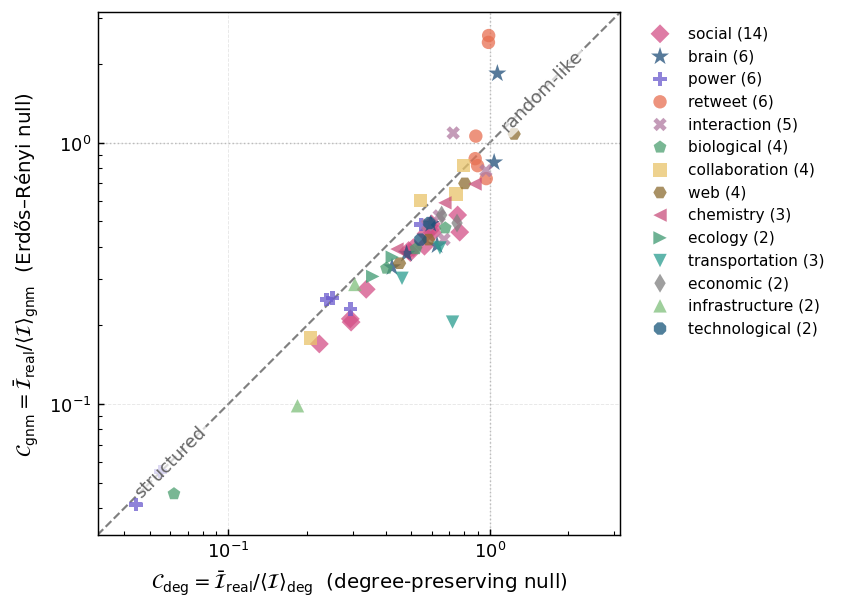

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

MPL = {"circle": "o", "square": "s", "diamond": "D", "thindiamond": "d", "plus": "P", "cross": "X", "star": "*",
       "triangle-up": "^", "triangle-down": "v", "triangle-left": "<", "triangle-right": ">",
       "pentagon": "p", "hexagon": "H", "octagon": "8"}
INCLUDE_ROAD = False

plt.rcParams.update({"font.size": 10, "axes.labelsize": 11, "axes.linewidth": 0.8,
                     "xtick.direction": "in", "ytick.direction": "in"})
d = df.dropna(subset=["C_deg", "C_gnm"])
if not INCLUDE_ROAD:
    d = d[d.group == "non-road"]

v = np.log10(np.r_[d.C_deg, d.C_gnm])
lim = (10 ** (np.floor(v.min() * 2) / 2), 10 ** (np.ceil(v.max() * 2) / 2))

fig, ax = plt.subplots(figsize=(7, 4.8), dpi=130)
ax.plot(lim, lim, "--", color="0.5", lw=1.2, zorder=0)
ax.axvline(1, color="0.75", lw=0.8, ls=":", zorder=0)
ax.axhline(1, color="0.75", lw=0.8, ls=":", zorder=0)
for c in CATS:
    s = d[d.cat == c["key"]]
    if len(s):
        ax.scatter(s.C_deg, s.C_gnm, marker=MPL[c["shape"]], s=110 if c["shape"] == "star" else 55,
                   color=to_rgba(c["color"], 0.75), edgecolors="none", label=f'{c["name"]} ({len(s)})', zorder=3)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(*lim); ax.set_ylim(*lim)
ax.set_aspect("equal", adjustable="box")
ax.grid(True, which="major", ls="--", lw=0.5, alpha=0.3)
ax.set_xlabel(r"$\mathcal{C}_{\rm deg}=\bar{\mathcal{I}}_{\rm real}/\langle\mathcal{I}\rangle_{\rm deg}$  (degree-preserving null)")
ax.set_ylabel(r"$\mathcal{C}_{\rm gnm}=\bar{\mathcal{I}}_{\rm real}/\langle\mathcal{I}\rangle_{\rm gnm}$  (Erdős–Rényi null)")
bg = dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.7)
ax.text(lim[0] * 1.35, lim[0] * 1.35, "structured", rotation=45, ha="left", va="bottom", fontsize=10, color="0.4", bbox=bg)
ax.text(lim[1] / 1.35, lim[1] / 1.35, "random-like", rotation=45, ha="right", va="top", fontsize=10, color="0.4", bbox=bg)
ax.legend(fontsize=8.5, ncol=1, frameon=False, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig('/Users/gahyoungim/Library/CloudStorage/GoogleDrive-dotchgahyoun@gmail.com/내 드라이브/Project-HONE/fig/C_geom.png', dpi = 300)
fig.savefig('/Users/gahyoungim/Library/CloudStorage/GoogleDrive-dotchgahyoun@gmail.com/내 드라이브/Project-HONE/fig/C_geom.pdf')
plt.show()